# Numerical Toy Problem for 1D-Diffusion

This notebook models the spread of a pollutant released at $x = 0$ using the one-dimensional diffusion equation:

$$
\partial_{t}C(x,t) = D \partial_{xx}C(x,t)
$$

With the following boundary conditions

\begin{align}
    C(x,0) &= \delta(x) && \text{on },\\
    C(\pm L, t) &= 0 && \text{on },\\
    C_x(x,0) &= && \text{in }.
\end{align}


In [55]:
# Window resizing
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))
display(HTML("<style>.output_resu1lt { width:90% !important; }</style>"))
display(HTML(""" <style>.output_png { display: table-cell; text-align: center; vertical-align: middle; }</style> """))
display(HTML("<style> div.text_cell_render { line-height: 2.0; } </style>"))    # Adjust linespread

In [56]:
# Baseline packages
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation
from scipy.sparse        import diags_array
from scipy.sparse.linalg import spsolve
%matplotlib inline

---

In [57]:
def I_1(x, M, delta_x):
    C0 = np.zeros_like(x, dtype=float)
    C0[len(x) // 2] = M / delta_x      # at x==0 C0[]
    return C0
    

b_1 = [0.0, 0.0]    # u(0,t) = b_0, u(1,t) = b_L

### Solve difference equations:

In [58]:
# ** Set up a plotting function ** #

def plotting(U, x, t, max_y=None, exact_handle=None, x_range=None):
    markers = ['x','s','d','+','o','.']
    colours = ['xkcd:salmon','xkcd:golden rod','xkcd:teal','xkcd:purple','xkcd:slate','xkcd:silver']    
    
    # choose some (almost arbitrary) display times
    N = len(t) - 1
    disp_times = [0, N//20, N//10, N//5, N//2, N]              

    # Set up the figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))

    # Dummy plot for legend titles
    ax.scatter([0], [0], color='white', label=r'Exact $u(x,t)$', lw=0)

    # Plot actual curves
    if exact_handle != None:
        for i, idx_t in enumerate(disp_times):
            label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < t[-1]) else 't = {0:.0f}'.format(t[idx_t])
            ax.plot(x, exact_handle(x,t[idx_t]),
        color="red",
        linestyle="--",
        label=label)

    ax.scatter([0], [0], color='white', label=r'Numerical $U(x,t)$', lw=0)
    for i, idx_t in enumerate(disp_times):
        label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < t[-1]) else 't = {0:.0f}'.format(t[idx_t])
        ax.plot(x, U[idx_t],
        linestyle='-',
        marker=markers[i],
        markevery=max(1, len(x)//40),
        color=colours[i],
        label=label)
        
    ax.legend(ncols = 2, loc = 'center',  bbox_to_anchor=(1.2, 0.5), title ='Comparison')
    if x_range:
        ax.set_xlim(x_range)
    else:
        ax.set_xlim(x[0], x[-1])

    ax.set_ylim(0,max_y)
    plt.xlabel("Space (x)")
    plt.ylabel("Solution")
    plt.grid()
    plt.show()

In [59]:
def solve_forward(D, mass, L, T=200, N=20000, density = 1 ,
                  max_y=45, x_range=None, exact_handle=None, plot=True,):
    Nx = int(density*L)  # Number of space steps
    t = np.linspace(0.0, T, N + 1)      # Time grid
    x = np.linspace(-L, L, Nx + 1)    # Space grid

    dx = x[1] - x[0] 
    dt = t[1] - t[0]

    r = D*dt/(dx**2) # stability condition

    print("r =", r)
    if r>=0.5:
        print("Not stable")
        return

    U = np.zeros((N+1,Nx+1))

    U[:, 0] = np.zeros((N+1))
    U[:, -1] = np.zeros((N+1))

    U[0] = I_1(x, mass, dx) 

    for n in range(0, N):
        """for m in range(0, M):
            U[n+1, m] = U[n, m] + C*(U[n, m+1] - 2*U[n, m] +U[n, m-1])"""
        U[n+1,1:-1] = U[n, 1:-1] + r*(U[n, :-2] - 2*U[n, 1:-1] + U[n, 2:])
    total_mass = U.sum(axis=1) * dx  

    print(total_mass)
    plotting(U, x, t, max_y, x_range, exact_handle)
    

    return U, x, t, total_mass


r = 0.005
[1000. 1000. 1000. ... 1000. 1000. 1000.]


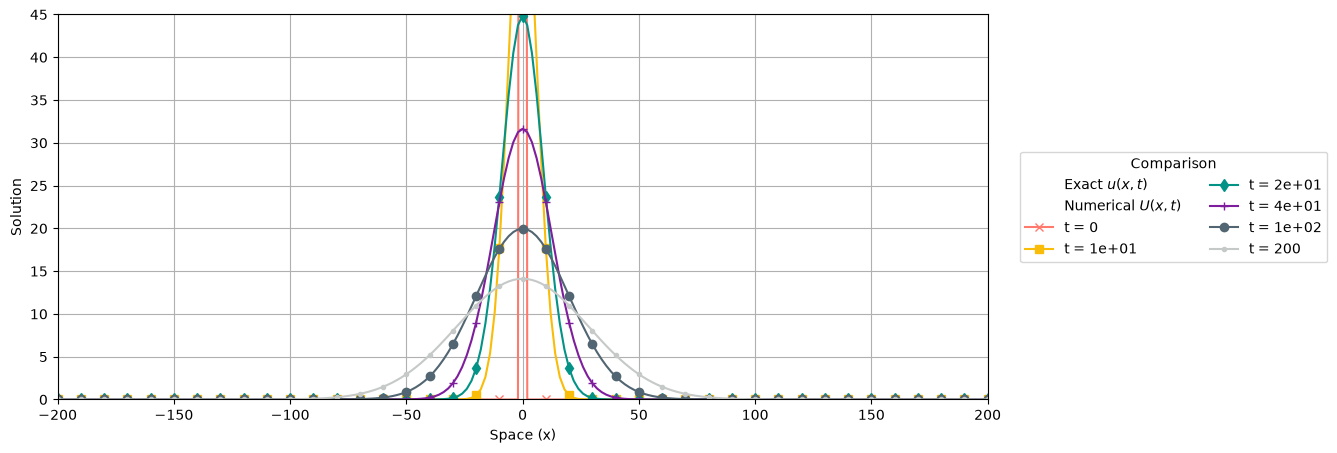

In [60]:
D, mass = 2.0, 1000
U, x, t, m = solve_forward(D, mass, L=200)
#not stable

r = 0.1
[1000. 1000. 1000. ... 1000. 1000. 1000.]


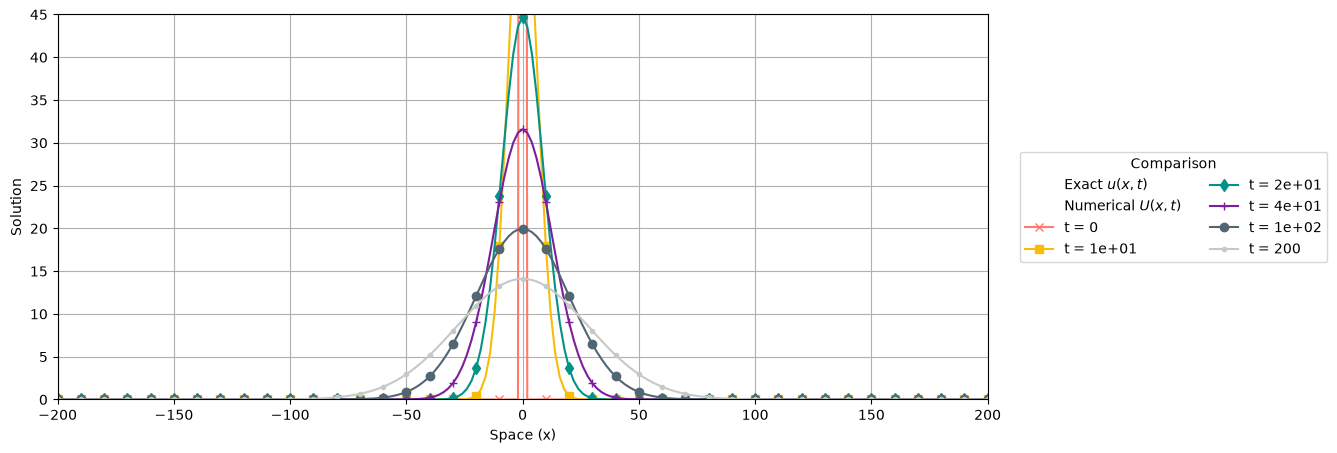

r = 0.1
[1000. 1000. 1000. ... 1000. 1000. 1000.]


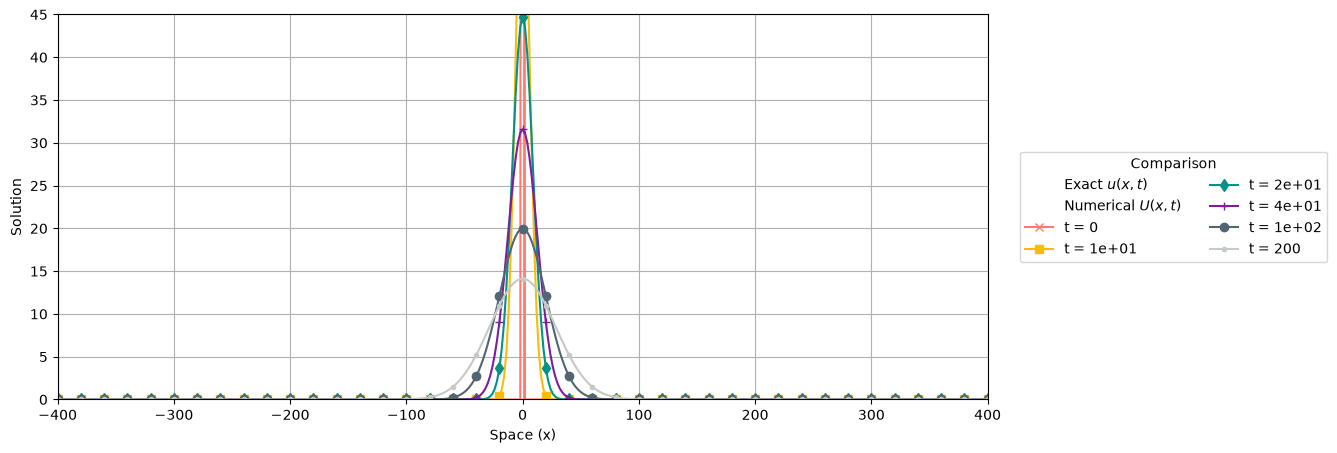

r = 0.1
[1000. 1000. 1000. ... 1000. 1000. 1000.]


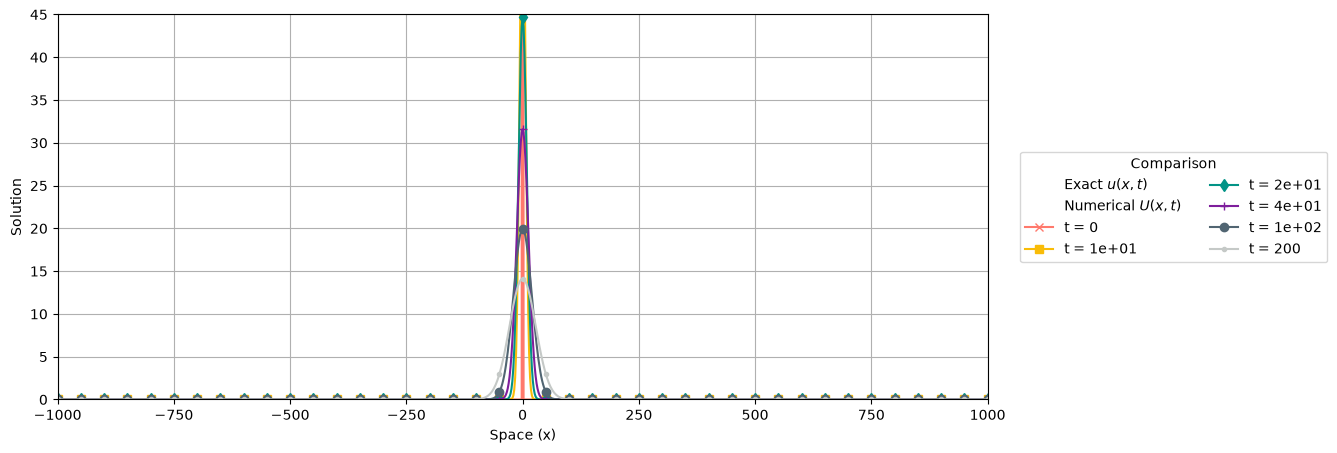

In [61]:
U1, x1, _, _ = solve_forward(D, mass, L=200, N=1000)
U2, x2, _, _ = solve_forward(D, mass, L=400, N=1000)
U3, x3, _, _ = solve_forward(D, mass, L=1000, N=1000)


### backward euler

In [62]:
def solve_backward(D, mass, L, max_y = None, exact_handle = None, x_range=None):
    N = 20000    # number of timesteps
    T = 200     # final time 
    t = np.linspace(0.0, T, N + 1)      # Time grid

    M = 1000    # number of spaces in x
    x = np.linspace(-L, L, M + 1)    # Space grid

    dx = x[1] - x[0] 
    dt = t[1] - t[0]

    C = D*dt/(dx**2) 

    diags = np.ones((3,M+1))

    diags[0,1:-1] += 2 * C             

    diags[1:] = - C;    

    diags[1,0] = 0.0

    diags[2,-2] = 0.0 


    A = diags_array(diags, offsets = (0,1,-1), shape = (M+1, M+1), format = 'csr')

    U = np.zeros((N+1,M+1))
    U[0] = I_1(x, mass, dx)
    U[:,[0,-1]] = b_1


    for n in range(0, N):
        U[n+1] = spsolve(A, U[n])

    plotting(U, x, t, max_y, exact_handle, x_range)



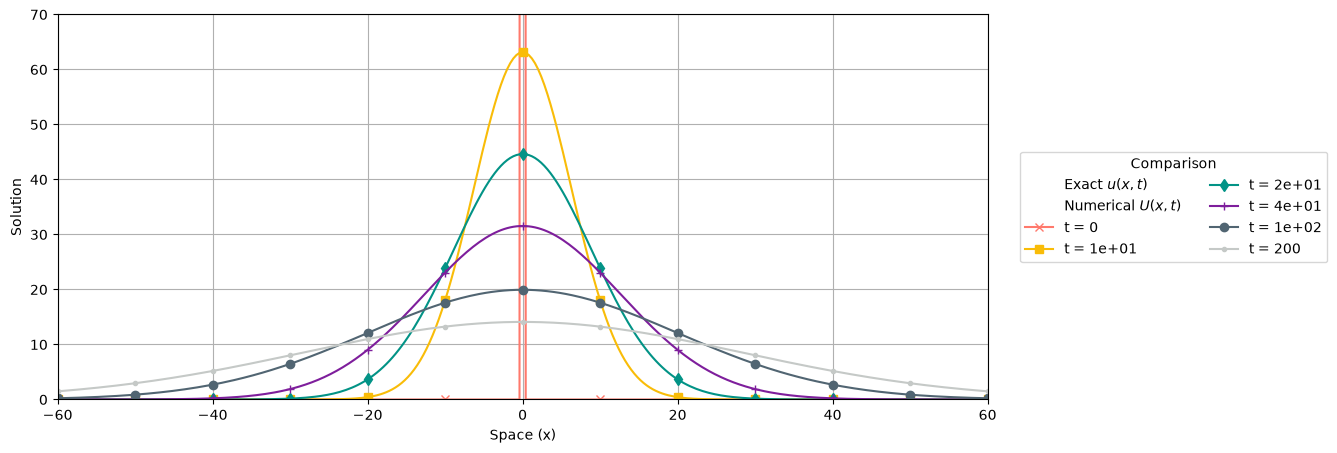

In [63]:
solve_backward(2, 1000, 200, max_y=70, x_range=(-60, 60))

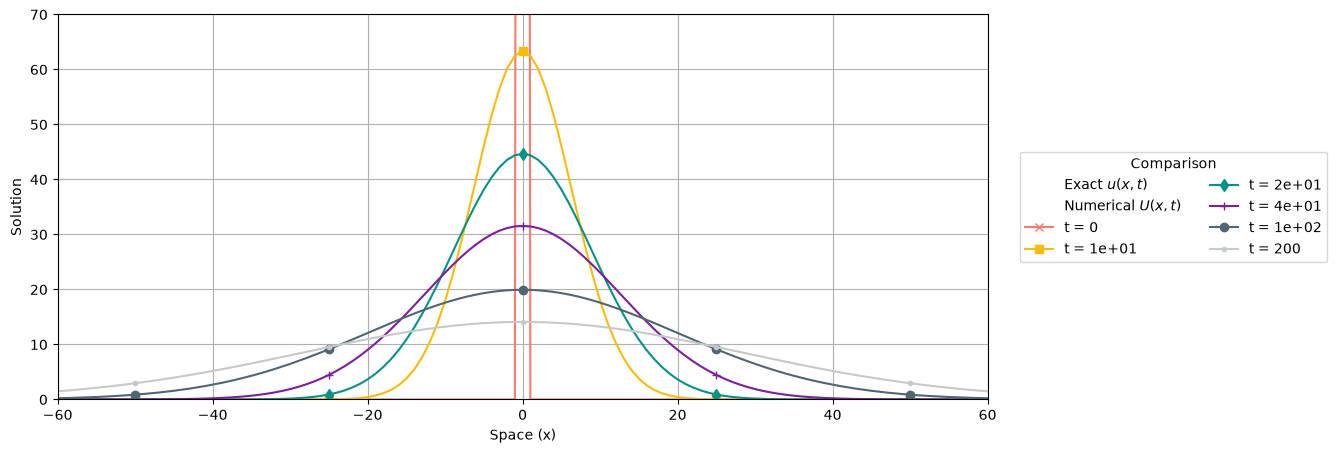

In [64]:
L  =500
solve_backward(2, 1000, L, max_y=70, x_range=(-60, 60))

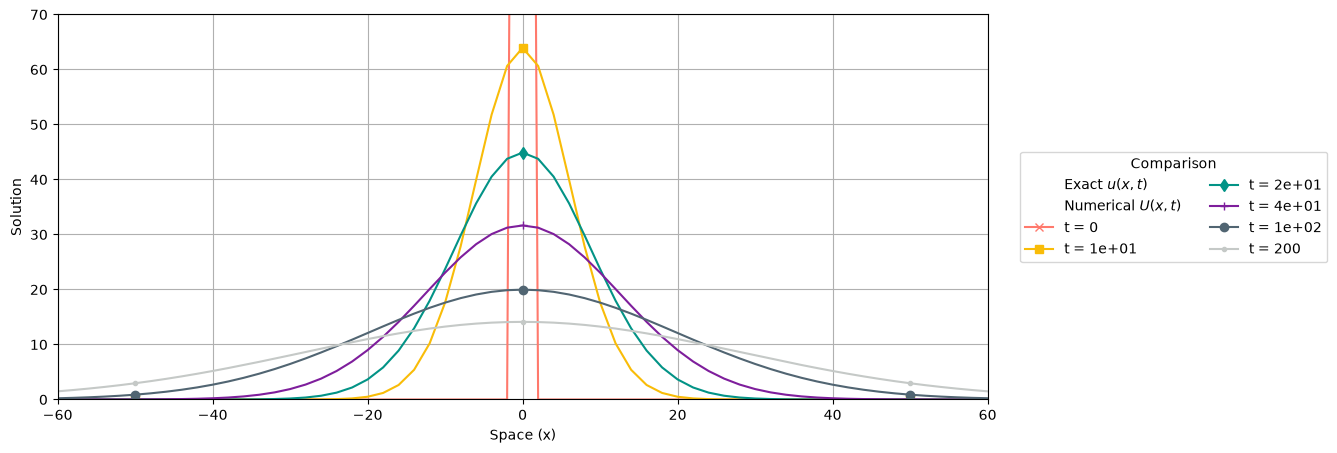

In [65]:
L  =1000
solve_backward(2, 1000, L, max_y=70, x_range=(-60, 60))

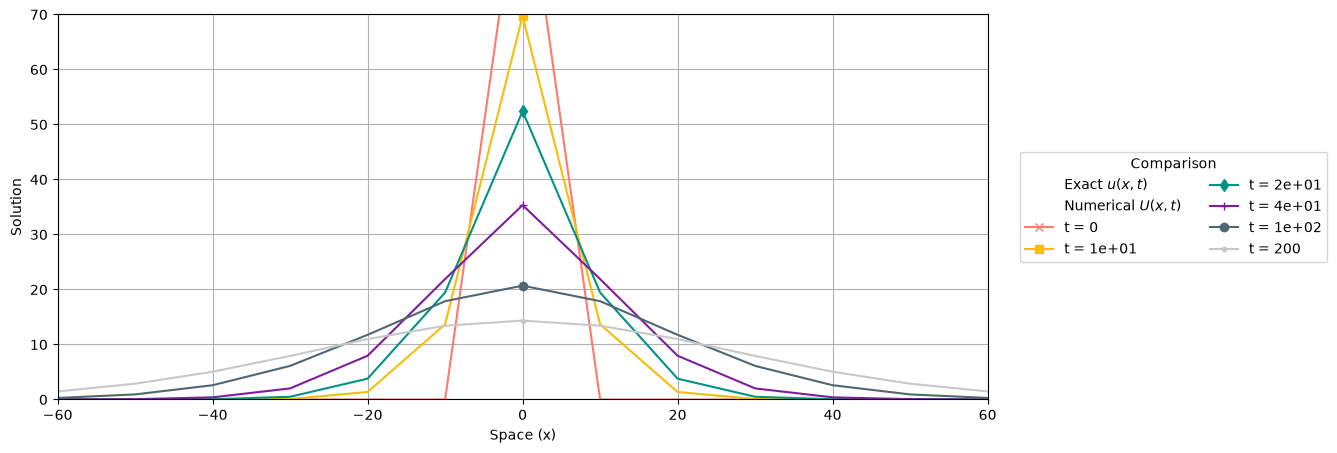

In [66]:
L  =5000
solve_backward(2, 1000, L, max_y=70, x_range=(-60, 60))